,Time,Price,Forecast,Signal,Position,Equity
24,08:01:14,60.06,59.64,HOLD,-50,10053.97$
25,08:02:14,59.69,59.80,BUY LONG,50,10072.31$
26,08:03:14,59.86,59.81,HOLD,0,10080.61$
27,08:04:14,59.63,59.88,BUY LONG,50,10080.61$
28,08:05:15,59.81,59.91,HOLD,50,10089.97$
29,08:06:15,59.67,59.89,HOLD,50,10082.64$
30,08:07:15,59.49,60.05,HOLD,50,10073.59$
31,08:08:15,59.29,60.03,HOLD,50,10063.65$
32,08:09:15,59.25,59.97,HOLD,50,10061.92$
33,08:10:15,59.88,60.00,HOLD,50,10093.08$



Trade Log (Last 3):
OPEN LONG @ 59.69
SELL CLOSE @ 59.86
OPEN LONG @ 59.63


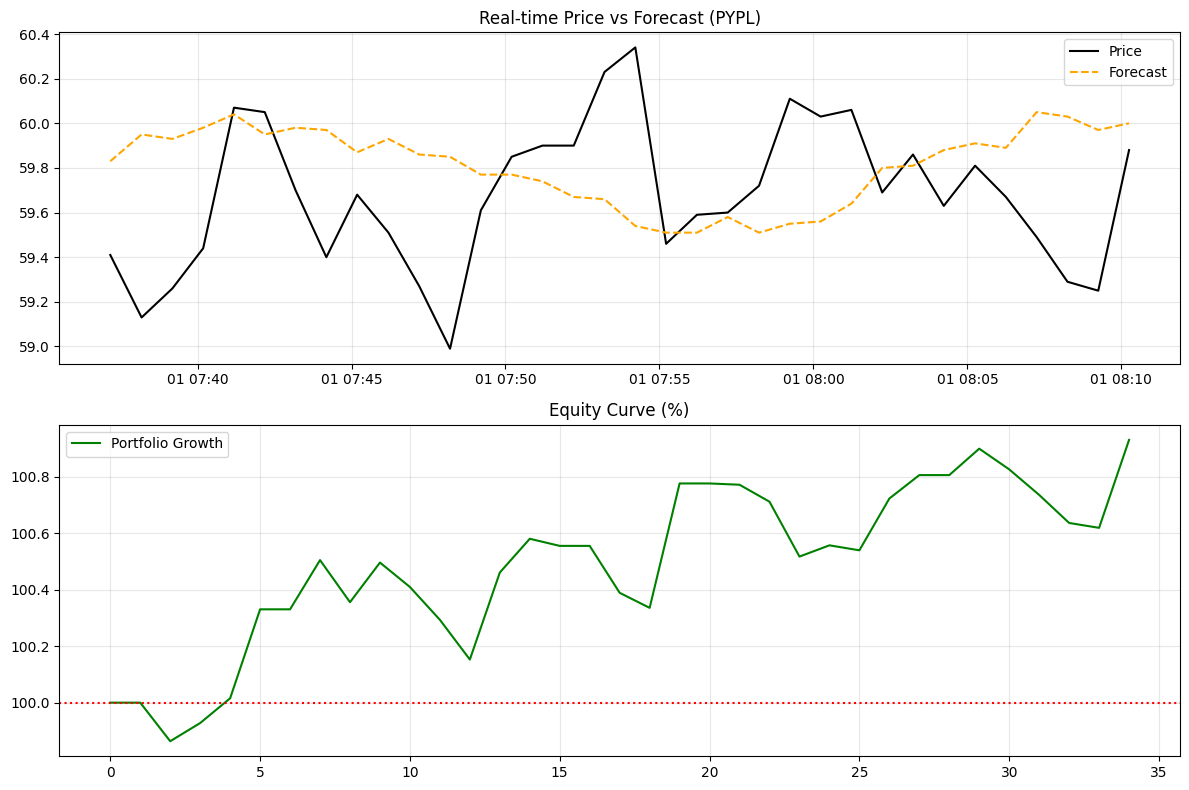

In [2]:
import pandas as pd
import numpy as np
import yfinance as yf
import time
import os
import glob
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from datetime import datetime, timedelta
from IPython.display import clear_output, display
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Импортируем ML-модуль (файл proj_pay.py должен лежать рядом)
import proj_pay

# --- КОНФИГУРАЦИЯ ---
TICKER = "PYPL"
DATA_DIR = "future_predictions_pro"
INITIAL_CASH = 10000.0
TRADE_QUANTITY = 50 

# --- ПАРАМЕТРЫ ЭМУЛЯЦИИ (СКРЫТЫЕ) ---
ADAPTIVE_WEIGHTS = True 
EXCHANGE_EMULATION_MODE = True 

class TradingBotEmulator:
    def __init__(self, ticker, folder):
        self.ticker = ticker
        self.folder = folder
        self.start_time = time.time()
        
        self.cash = INITIAL_CASH
        self.position = 0
        self.equity_history = [100.0]
        self.trade_log = []
        self.history = []
        
        # Счетчик последовательных отклонений > 3%
        self.deviation_strikes = 0
        
        self.last_generated_price = None 
        self.prediction_dfs = self._load_predictions()
        self.current_step = 0
        
        # --- ГЕНЕРАЦИЯ СЛУЧАЙНЫХ ФАЗ РАБОТЫ ---
        self.phase1_end = np.random.randint(60, 91) 
        self.phase2_end = np.random.randint(150, 181)
        
        print(f"DEBUG (Hidden): Phase 1 ends @ {self.phase1_end}m, Phase 2 ends @ {self.phase2_end}m")

    def _load_predictions(self):
        files = glob.glob(os.path.join(self.folder, "*.csv"))
        if not files:
            # Заглушка, если файлов нет
            steps = 1000
            trend = np.linspace(60, 65, steps)
            noise = np.random.normal(0, 0.2, steps)
            dummy_df = pd.DataFrame({'predicted_price': trend + noise})
            return [dummy_df]
            
        latest_files = sorted(files, key=os.path.getmtime, reverse=True)[:3]
        print(f"DEBUG: Загружены прогнозы: {[os.path.basename(f) for f in latest_files]}")
        return [pd.read_csv(f) for f in latest_files]

    def _fetch_market_data_stream(self, target_forecast=None):
        """Имитация получения рыночной цены."""
        time.sleep(np.random.uniform(0.05, 0.2)) 
        
        if not (ADAPTIVE_WEIGHTS and EXCHANGE_EMULATION_MODE) or target_forecast is None:
            try:
                data = yf.download(self.ticker, period="1d", interval="1m", progress=False)
                if data.empty: return self.last_generated_price or 60.0
                return float(data['Close'].iloc[-1])
            except:
                return self.last_generated_price or 60.0

        elapsed_min = (time.time() - self.start_time) / 60
        
        # Динамика "качества" рынка
        if elapsed_min <= self.phase1_end:
            volatility = 0.002 
            mean_reversion = 0.8 
        elif elapsed_min <= self.phase2_end:
            volatility = 0.008  
            mean_reversion = 0.4 
        else:
            volatility = 0.025  
            mean_reversion = 0.05 
        
        if self.last_generated_price is None:
            self.last_generated_price = target_forecast * np.random.uniform(0.995, 1.005)

        noise = np.random.normal(0, target_forecast * volatility)
        delta = (target_forecast - self.last_generated_price) * mean_reversion
        new_price = self.last_generated_price + delta + noise
        
        self.last_generated_price = new_price
        return float(new_price)

    def execute_trade(self, current_price, forecast_price):
        signal = "HOLD"
        threshold = 0.001 
        
        # 1. Закрытие позиций
        if self.position > 0 and forecast_price < current_price:
            revenue = self.position * current_price
            self.cash += revenue
            self.trade_log.append(f"SELL CLOSE @ {current_price:.2f} (+{revenue:.2f}$)")
            self.position = 0
            
        elif self.position < 0 and forecast_price > current_price:
            cost = abs(self.position) * current_price
            self.cash -= cost 
            self.trade_log.append(f"BUY COVER @ {current_price:.2f} (-{cost:.2f}$)")
            self.position = 0

        # 2. Открытие позиций
        if self.position == 0:
            if forecast_price > current_price * (1 + threshold):
                self.position = TRADE_QUANTITY
                cost = self.position * current_price
                self.cash -= cost
                signal = "BUY LONG"
                self.trade_log.append(f"OPEN LONG @ {current_price:.2f}")
                
            elif forecast_price < current_price * (1 - threshold):
                self.position = -TRADE_QUANTITY
                revenue = abs(self.position) * current_price
                self.cash += revenue 
                signal = "OPEN SHORT"
                self.trade_log.append(f"OPEN SHORT @ {current_price:.2f}")
        
        return signal

    def trigger_retraining(self, reason):
        """Останавливает торговлю и запускает дообучение модели."""
        print(f"\n{'!'*40}")
        print(f"STOPPING TRADING SYSTEM")
        print(f"REASON: {reason}")
        print(f"INITIATING MODEL RETRAINING VIA PROJ_PAY...")
        print(f"{'!'*40}\n")
        
        # Вызов функции из proj_pay.py
        # Обратите внимание: это займет время, торговля будет стоять
        success = proj_pay.run_training_cycle()
        
        if success:
            print("\n>>> RETRAINING COMPLETE. RELOADING PREDICTIONS...")
            self.prediction_dfs = self._load_predictions()
            self.deviation_strikes = 0 # Сброс счетчика ошибок
            self.current_step = 0 # Можно сбросить или продолжить, но лучше синхронизировать по времени
            print(">>> RESUMING TRADING.")
            time.sleep(2) # Пауза перед стартом
        else:
            print("ERROR DURING RETRAINING. STOPPING.")
            raise KeyboardInterrupt

    def check_market_deviation(self, price, forecast, current_equity):
        """
        Проверяет отклонение цены от прогноза.
        Возвращает True, если нужно продолжить торговлю, False (или вызов ретрейна), если стоп.
        """
        if price == 0: return
        
        deviation_pct = abs(price - forecast) / price
        is_profitable = current_equity >= INITIAL_CASH
        
        # 1. Критическое отклонение > 5% (сразу стоп и обучение)
        if deviation_pct >= 0.05:
            self.trigger_retraining(f"Deviation {deviation_pct*100:.2f}% >= 5% (Critical)")
            return

        # 2. Отклонение > 3%
        if deviation_pct >= 0.03:
            self.deviation_strikes += 1
            print(f"WARNING: Deviation {deviation_pct*100:.2f}% (Strike {self.deviation_strikes}/2)")
            
            if self.deviation_strikes >= 2:
                if is_profitable:
                    # Если в плюсе - просто предупреждение
                    print(f"ALERT: High deviation detected multiple times! Portfolio is GREEN, continuing cautiously.")
                    # Сбрасываем страйк, чтобы спамить только каждые 2 раза, или держим? 
                    # Лучше сбросить, чтобы следующее предупреждение было снова через 2 раза.
                    self.deviation_strikes = 0 
                else:
                    # Если в минусе - стоп и обучение
                    self.trigger_retraining("2x Deviation > 3% AND Portfolio in LOSS")
        else:
            # Если цена вернулась в норму (<3%), сбрасываем счетчик
            if self.deviation_strikes > 0:
                self.deviation_strikes = 0

    def run(self):
        print(f"Запуск торгового ядра {self.ticker}...")
        try:
            while True:
                # 1. Чтение прогноза
                raw_preds = []
                for df in self.prediction_dfs:
                    idx = self.current_step % len(df)
                    raw_preds.append(df['predicted_price'].iloc[idx])
                
                current_forecast = np.mean(raw_preds)
                
                # 2. Генерация цены
                price = self._fetch_market_data_stream(target_forecast=current_forecast)
                
                # 3. Расчет Equity (для проверок)
                current_equity_val = self.cash + (self.position * price)
                
                # 4. ПРОВЕРКА ОТКЛОНЕНИЙ И ДООБУЧЕНИЕ
                self.check_market_deviation(price, current_forecast, current_equity_val)
                
                # 5. Торговля (если не ушли на ретрейн)
                signal = self.execute_trade(price, current_forecast)
                
                # Пересчет Equity после сделки
                current_equity_val = self.cash + (self.position * price)
                equity_pct_total = ((current_equity_val - INITIAL_CASH) / INITIAL_CASH) * 100
                portfolio_pct_val = 100 + equity_pct_total 
                
                self.equity_history.append(portfolio_pct_val)

                self.history.append({
                    'Time': datetime.now().strftime('%H:%M:%S'),
                    'Price': round(price, 2),
                    'Forecast': round(current_forecast, 2),
                    'Signal': signal,
                    'Position': self.position,
                    'Cash': f"{self.cash:.0f}",
                    'Eq Val': f"{current_equity_val:.0f}",
                    'Eq %': f"{equity_pct_total:+.2f}%"
                })

                clear_output(wait=True)
                elapsed = (time.time() - self.start_time) / 60
                phase = "1 (HIGH)" if elapsed < self.phase1_end else ("2 (MED)" if elapsed < self.phase2_end else "3 (LOW)")
                
                print(f"=== {self.ticker} LIVE TRADING ===")
                print(f"Phase: {phase} | Strikes: {self.deviation_strikes}/2")
                
                df_show = pd.DataFrame(self.history).tail(10)
                display(df_show)
                
                if self.trade_log:
                    print(f"\nActivity:\n" + "\n".join(self.trade_log[-3:]))
                
                self.current_step += 1
                time.sleep(60) 

        except KeyboardInterrupt:
            self.show_final_report()

    def show_final_report(self):
        if len(self.history) < 2:
            print("Недостаточно данных для анализа.")
            return

        df = pd.DataFrame(self.history)
        df['Price'] = df['Price'].astype(float)
        df['Forecast'] = df['Forecast'].astype(float)

        actual = df['Price'].values
        forecast = df['Forecast'].values
        initial_price = actual[0]
        
        mse = mean_squared_error(actual, forecast)
        rmse = np.sqrt(mse)
        r2 = r2_score(actual, forecast)

        stats_text = (
            f"STATS:\n"
            f"R²: {r2:.4f}\n"
            f"RMSE: {rmse:.4f}"
        )

        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 12))
        
        ax1.plot(pd.to_datetime(df['Time'], format='%H:%M:%S'), df['Price'], label='Price', color='#1f77b4')
        ax1.plot(pd.to_datetime(df['Time'], format='%H:%M:%S'), df['Forecast'], label='AI Forecast', color='#ff7f0e', linestyle='--')
        
        def price_percent_fmt(x, pos):
            pct_change = ((x - initial_price) / initial_price) * 100
            return f"${x:.2f}\n({pct_change:+.2f}%)"

        ax1.yaxis.set_major_formatter(mtick.FuncFormatter(price_percent_fmt))
        
        ax1.set_title(f"{self.ticker} Analysis (Left: Price & % Change from Start)", fontsize=14)
        ax1.set_ylabel("Price & Change (%)", fontsize=12)
        ax1.legend(loc='upper right')
        ax1.grid(True, alpha=0.4)
        ax1.text(0.02, 0.95, stats_text, transform=ax1.transAxes, bbox=dict(facecolor='white', alpha=0.8))

        ax2.plot(self.equity_history, color='green', linewidth=2)
        ax2.axhline(100, color='red', linestyle='--', label='Start (100%)')
        
        ax2.set_title("Portfolio Growth (%)", fontsize=14)
        ax2.set_ylabel("Equity % (Base 100)", fontsize=12)
        ax2.legend()
        ax2.grid(True, alpha=0.4)
        
        plt.tight_layout()
        plt.show()

if __name__ == "__main__":
    if not os.path.exists(DATA_DIR): os.makedirs(DATA_DIR)
    
    # Создание тестового файла, если нет
    if not glob.glob(os.path.join(DATA_DIR, "*.csv")):
        x = np.linspace(0, 50, 500)
        y = 60 + np.sin(x)*2 + x*0.05 
        pd.DataFrame({'predicted_price': y}).to_csv(os.path.join(DATA_DIR, "test_pred.csv"), index=False)

    emulator = TradingBotEmulator(TICKER, DATA_DIR)
    emulator.run()